# DE + mlp: binary cross-subject classification
Five-band FACED DE, subject-disjoint validation and the same splits as the SVM baseline.


## Imports


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import copy
import hashlib
import json
import pickle
import time
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import sem
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix
from threadpoolctl import threadpool_limits

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding='utf-8')

def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8*1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()

## Config


In [2]:
model_kind = 'mlp'
artifact_root = Path('D:/EEG Experiment Artifacts/2026-11-02')
experiment_root = artifact_root/'simple_models_de'
dataset_root = Path('C:/FACED dataset')
run_dir = experiment_root/model_kind
run_dir.mkdir(parents=True, exist_ok=True)
run_training = True
seed = 42
cpu_threads = 4
selected_videos = np.r_[0:12, 16:28]
channels = ['Fp1','Fp2','Fz','F3','F4','F7','F8','FC1','FC2','FC5','FC6',
            'Cz','C3','C4','T7','T8','CP1','CP2','CP5','CP6','Pz','P3','P4',
            'P7','P8','PO3','PO4','Oz','O1','O2']
class_names = ['Negative', 'Positive']
all_grids = {
 'mlp': [dict(hidden=[64,32], dropout=0.2, learning_rate=0.001, weight_decay=0.0001),
         dict(hidden=[128,64], dropout=0.2, learning_rate=0.001, weight_decay=0.0001)],
 'lda': [dict(shrinkage='auto')],
 'logistic_regression': [dict(C=c) for c in [0.001,0.1,10.0]],
 'extra_trees': [dict(n_estimators=200,max_depth=None,min_samples_leaf=5,max_features='sqrt'),
                 dict(n_estimators=200,max_depth=20,min_samples_leaf=20,max_features=0.5)],
 'hist_gradient_boosting': [dict(max_iter=150,max_leaf_nodes=15,learning_rate=0.1,min_samples_leaf=50,l2_regularization=1.0),
                           dict(max_iter=150,max_leaf_nodes=31,learning_rate=0.05,min_samples_leaf=50,l2_regularization=1.0)]}
candidate_grid = all_grids[model_kind]
mlp_training = dict(max_epochs=60,patience=8,batch_size=1024,selection='validation balanced accuracy; first best epoch',
                    loss='BCEWithLogitsLoss',optimizer='AdamW')
versions = {'python':__import__('platform').python_version(),'numpy':np.__version__,'sklearn':sklearn.__version__}
if model_kind == 'mlp':
    import torch
    from torch import nn
    torch.set_num_threads(cpu_threads)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    versions['torch'] = torch.__version__
    print('MLP device:', device, torch.cuda.get_device_name(0) if device.type=='cuda' else '')
print('Model:', model_kind, '| DE only | candidates:', len(candidate_grid))
print('Subject-disjoint validation selects settings. No refit on validation subjects.')

MLP device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
Model: mlp | DE only | candidates: 2
Subject-disjoint validation selects settings. No refit on validation subjects.


## Data


In [3]:
input_paths = [dataset_root/'EEG_Features/DE'/f'sub{s:03d}.pkl.pkl' for s in range(123)]
input_hashes = {str(p):file_hash(p) for p in input_paths}
cache_dir = experiment_root/'cache'
cache_dir.mkdir(exist_ok=True)
feature_path = cache_dir/'de_features.npy'
expected_shape = (2952,30,30,5)
if not feature_path.exists():
    values = np.empty((123,24,30,30,5),dtype=np.float32)
    for sub,p in enumerate(input_paths):
        with p.open('rb') as stream:
            source = np.asarray(pickle.load(stream))
        assert source.shape == (28,32,30,5) and np.isfinite(source).all()
        values[sub] = source[selected_videos,:30].transpose(0,2,1,3)
    np.save(feature_path, values.reshape(expected_shape))
    del values
features = np.load(feature_path,mmap_mode='r')
assert features.shape == expected_shape and features.dtype == np.float32
for sub,p in enumerate(input_paths):
    with p.open('rb') as stream:
        source = np.asarray(pickle.load(stream))
    expected = source[selected_videos,:30].transpose(0,2,1,3).astype(np.float32)
    assert np.array_equal(features[sub*24:(sub+1)*24],expected)
del source,expected
subjects = np.repeat(np.arange(123),24)
videos = np.tile(selected_videos+1,123)
video_labels = np.r_[np.zeros(12,dtype=int),np.ones(12,dtype=int)]
trial_labels = np.tile(video_labels,123)
splits = []
for fold in range(10):
    test = np.arange(fold*12,(fold+1)*12 if fold<9 else 123)
    remaining = np.setdiff1d(np.arange(123),test)
    shuffled = np.random.default_rng(seed+fold).permutation(remaining)
    n_val = round(0.2*len(remaining))
    val,train = np.sort(shuffled[:n_val]),np.sort(shuffled[n_val:])
    assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    splits.append({'fold':fold,'train':train.tolist(),'val':val.tolist(),'test':test.tolist()})
assert sorted(s for split in splits for s in split['test']) == list(range(123))
protocol = {'seed':seed,'classes':2,'features':'official five-band DE, first 30 channels',
            'bands':[[1,4],[4,8],[8,14],[14,30],[30,47]],'channels':channels,
            'selected_video_ids':(selected_videos+1).tolist(),'feature_order':'channel then band',
            'scaling':'train-only mean/std; floor 1e-6; float32 transform then float64 storage',
            'normalization_and_smoothing':'no running normalization or LDS',
            'splits':splits,'input_hashes':input_hashes,'feature_cache_sha256':file_hash(feature_path),
            'selection':'inner validation balanced accuracy; ties use first candidate',
            'refit_validation':False,'evaluation':'one-second predictions, one held-out test fold per subject'}
protocol_hash = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
p = experiment_root/'protocol.json'
if p.exists(): assert json.loads(p.read_text()) == protocol
else: save_json(p,protocol)
svm_protocol_path = artifact_root/'svm_feature_ablation/protocol.json'
if svm_protocol_path.exists():
    svm_protocol = json.loads(svm_protocol_path.read_text())
    assert svm_protocol['splits'] == splits
    assert all(svm_protocol['input_hashes'][p]==h for p,h in input_hashes.items())
    assert svm_protocol['settings']['channels'] == channels
    assert svm_protocol['settings']['selected_video_ids'] == (selected_videos+1).tolist()
settings = {'model':model_kind,'candidate_grid':candidate_grid,'mlp_training':mlp_training if model_kind=='mlp' else None,
            'versions':versions,'seed':seed,'protocol_hash':protocol_hash,'cpu_threads':cpu_threads}
settings_hash = hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()
p = run_dir/'config.json'
if p.exists(): assert json.loads(p.read_text()) == settings
else: save_json(p,settings)
print('123 subjects | 24 videos per subject | 150 DE features per second | 88560 predictions')
print('Same splits, channels, DE values and scaling as the earlier DE + linear SVM baseline.')

123 subjects | 24 videos per subject | 150 DE features per second | 88560 predictions
Same splits, channels, DE values and scaling as the earlier DE + linear SVM baseline.


## Prepare folds


In [4]:
def trial_indices(people):
    return np.flatnonzero(np.isin(subjects,people))

def fold_data(split):
    directory = cache_dir/f"fold_{split['fold']:02d}"
    directory.mkdir(exist_ok=True)
    meta_path = directory/'metadata.json'
    if not meta_path.exists():
        x = features[trial_indices(split['train'])]
        mean = x.mean(axis=(0,1),dtype=np.float64).astype(np.float32)
        std = np.maximum(x.std(axis=(0,1),dtype=np.float64),1e-6).astype(np.float32)
        np.savez(directory/'scaler.npz',mean=mean,std=std,training_subjects=split['train'],protocol_hash=protocol_hash)
        original_scaler = artifact_root/'svm_feature_ablation/scalers'/f"fold_{split['fold']:02d}.npz"
        if original_scaler.exists():
            old = np.load(original_scaler)
            assert np.array_equal(mean,old['mean'][:,:5]) and np.array_equal(std,old['std'][:,:5])
        files = {}
        for group in ['train','val','test']:
            idx = trial_indices(split[group])
            z = np.ascontiguousarray(((features[idx].copy()-mean)/std).reshape(-1,150),dtype=np.float64)
            assert np.isfinite(z).all()
            path = directory/f'{group}.npy'
            np.save(path,z,allow_pickle=False)
            files[path.name] = file_hash(path)
        save_json(meta_path,{'protocol_hash':protocol_hash,'split':split,'sha256':files,
                             'scaler_sha256':file_hash(directory/'scaler.npz'),'shape_per_second':[150],
                             'dtype':'float64','feature_order':'channel then band','label_order':'trial then second'})
    meta = json.loads(meta_path.read_text())
    assert meta['protocol_hash']==protocol_hash and meta['split']==split
    assert file_hash(directory/'scaler.npz')==meta['scaler_sha256']
    arrays = {}
    for group in ['train','val','test']:
        p = directory/f'{group}.npy'
        assert file_hash(p)==meta['sha256'][p.name]
        idx = trial_indices(split[group])
        x = np.load(p,mmap_mode='r')
        y = np.repeat(trial_labels[idx],30)
        assert x.shape==(len(y),150) and x.dtype==np.float64
        arrays[group] = (x,y,idx)
    return arrays

def metrics(y,pred,score):
    return {'accuracy':float(accuracy_score(y,pred)), 'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,average='macro')), 'roc_auc':float(roc_auc_score(y,score))}

## Model


In [5]:
def make_model(params,fold_seed):
    if model_kind=='lda': return LinearDiscriminantAnalysis(solver='lsqr',**params)
    if model_kind=='logistic_regression': return LogisticRegression(solver='lbfgs',max_iter=2000,tol=1e-6,random_state=fold_seed,**params)
    if model_kind=='extra_trees': return ExtraTreesClassifier(n_jobs=cpu_threads,random_state=fold_seed,**params)
    if model_kind=='hist_gradient_boosting':
        return HistGradientBoostingClassifier(early_stopping=False,max_bins=127,random_state=fold_seed,**params)
    raise ValueError(model_kind)

def make_mlp(params):
    layers = []; width = 150
    for hidden in params['hidden']:
        layers += [nn.Linear(width,hidden),nn.ReLU(),nn.Dropout(params['dropout'])]
        width = hidden
    return nn.Sequential(*layers,nn.Linear(width,1))

def predict_model(model,x):
    if model_kind!='mlp':
        with threadpool_limits(limits=cpu_threads):
            probability = model.predict_proba(x)[:,1]
        return (probability>0.5).astype(np.int64),probability
    model.eval(); scores = []
    with torch.inference_mode():
        for i in range(0,len(x),8192):
            batch = torch.from_numpy(np.array(x[i:i+8192],dtype=np.float32,copy=True)).to(device)
            scores.append(model(batch).squeeze(1).sigmoid().cpu().numpy().astype(np.float64))
    probability = np.concatenate(scores)
    return (probability>0.5).astype(np.int64),probability

def load_model(folder,params):
    if model_kind!='mlp': return joblib.load(folder/'model.joblib')
    model = make_mlp(params).to(device)
    model.load_state_dict(torch.load(folder/'model.pt',map_location=device,weights_only=True))
    return model

def fit_mlp(params,train,val,folder,fold_seed):
    torch.manual_seed(fold_seed)
    if device.type=='cuda': torch.cuda.manual_seed_all(fold_seed)
    model = make_mlp(params).to(device)
    optimizer = torch.optim.AdamW(model.parameters(),lr=params['learning_rate'],weight_decay=params['weight_decay'])
    criterion = nn.BCEWithLogitsLoss()
    x = torch.from_numpy(np.array(train[0],dtype=np.float32,copy=True)).to(device)
    y = torch.from_numpy(train[1].astype(np.float32)).to(device)
    history = []; best = -1.; best_epoch = 0; stale = 0
    for epoch in range(1,mlp_training['max_epochs']+1):
        model.train(); order = torch.randperm(len(y),device=device); total = 0.
        for idx in order.split(mlp_training['batch_size']):
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x[idx]).squeeze(1),y[idx])
            loss.backward(); optimizer.step()
            total += float(loss.detach())*len(idx)
        pred,prob = predict_model(model,val[0]); measured = metrics(val[1],pred,prob)
        history.append({'epoch':epoch,'train_loss':total/len(y),**{'val_'+k:v for k,v in measured.items()}})
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if measured['balanced_accuracy']>best:
            best = measured['balanced_accuracy']; best_epoch = epoch; stale = 0
            torch.save(model.state_dict(),folder/'model.pt')
        else: stale += 1
        if epoch==1 or epoch%10==0: print('MLP epoch',epoch,'val BAcc',round(measured['balanced_accuracy'],4),flush=True)
        if stale>=mlp_training['patience']: break
    del x,y,optimizer,model
    if device.type=='cuda': torch.cuda.empty_cache()
    return load_model(folder,params),{'epochs_run':epoch,'best_epoch':best_epoch}

def candidate(split,index,arrays):
    folder = run_dir/f"fold_{split['fold']:02d}"/f'candidate_{index:02d}'
    folder.mkdir(parents=True,exist_ok=True)
    params = candidate_grid[index]
    config = {'settings_hash':settings_hash,'split':split,'candidate':index,'params':params}
    p = folder/'config.json'
    if p.exists(): assert json.loads(p.read_text())==config
    else: save_json(p,config)
    p = folder/'result.json'
    if p.exists(): return load_model(folder,params),json.loads(p.read_text())
    started = time.perf_counter(); caught_messages = []; extra = {}
    if model_kind=='mlp':
        model,extra = fit_mlp(params,arrays['train'],arrays['val'],folder,seed+split['fold'])
    else:
        model = make_model(params,seed+split['fold'])
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=cpu_threads):
            warnings.simplefilter('always')
            model.fit(arrays['train'][0],arrays['train'][1])
        caught_messages = [str(w.message) for w in caught]
        if any(issubclass(w.category,ConvergenceWarning) for w in caught):
            raise RuntimeError('Nonconverged fit: '+str(caught_messages))
        joblib.dump(model,folder/'model.joblib')
    pred,prob = predict_model(model,arrays['val'][0])
    row = {'candidate':index,'params':params,'seconds':time.perf_counter()-started,'warnings':caught_messages,
           'validation':metrics(arrays['val'][1],pred,prob),**extra}
    np.savez_compressed(folder/'validation_predictions.npz',predictions=pred,labels=arrays['val'][1],probability=prob)
    save_json(p,row)
    print('CANDIDATE COMPLETE',model_kind,'fold',split['fold'],'candidate',index,'val BAcc',round(row['validation']['balanced_accuracy'],4),'seconds',round(row['seconds'],2),flush=True)
    return model,row

## Evaluation


In [6]:
def run_fold(split):
    folder = run_dir/f"fold_{split['fold']:02d}"
    folder.mkdir(exist_ok=True)
    config = {'settings_hash':settings_hash,'split':split,'n_features':150}
    p = folder/'config.json'
    if p.exists(): assert json.loads(p.read_text())==config
    else: save_json(p,config)
    if (folder/'metrics.json').exists():
        print('Restored',model_kind,'fold',split['fold'],flush=True)
        return json.loads((folder/'metrics.json').read_text())
    arrays = fold_data(split); rows = []; best_row = None; best_model = None
    for index in range(len(candidate_grid)):
        model,row = candidate(split,index,arrays); rows.append(row)
        if best_row is None or row['validation']['balanced_accuracy']>best_row['validation']['balanced_accuracy']:
            best_model,best_row = model,row
        save_json(folder/'validation_grid.json',rows)
    # Test predictions are made only after the validation selection is frozen.
    pred,prob = predict_model(best_model,arrays['test'][0])
    y = arrays['test'][1]; idx = arrays['test'][2]
    np.savez_compressed(folder/'predictions.npz',predictions=pred.reshape(-1,30),labels=y.reshape(-1,30),
                        probability=prob.reshape(-1,30),subjects=subjects[idx],videos=videos[idx])
    extension = 'model.pt' if model_kind=='mlp' else 'model.joblib'
    import shutil
    shutil.copy2(folder/f"candidate_{best_row['candidate']:02d}"/extension,folder/extension)
    result = {'fold':split['fold'],'test_subjects':split['test'],'best_candidate':best_row['candidate'],
              'params':best_row['params'],'validation':best_row['validation'],'test':metrics(y,pred,prob),
              'candidate_fit_seconds':sum(row['seconds'] for row in rows)}
    save_json(folder/'metrics.json',result)
    print('FOLD COMPLETE',model_kind,json.dumps(result),flush=True)
    return result

def summarize():
    predictions = np.full((123,24,30),-1,dtype=np.int64)
    probabilities = np.full((123,24,30),np.nan,dtype=np.float64); results = []
    for split in splits:
        folder = run_dir/f"fold_{split['fold']:02d}"
        results.append(json.loads((folder/'metrics.json').read_text()))
        saved = np.load(folder/'predictions.npz')
        for sub in split['test']:
            mask = saved['subjects']==sub
            assert np.array_equal(saved['videos'][mask],selected_videos+1)
            predictions[sub] = saved['predictions'][mask]; probabilities[sub] = saved['probability'][mask]
    targets = np.tile(np.repeat(video_labels[:,None],30,axis=1)[None],(123,1,1))
    assert (predictions>=0).all() and np.isfinite(probabilities).all()
    people = [{'subject':s,**metrics(targets[s].ravel(),predictions[s].ravel(),probabilities[s].ravel())} for s in range(123)]
    pd.DataFrame(people).to_csv(run_dir/'subject_metrics.csv',index=False)
    np.savez_compressed(run_dir/'out_of_fold_predictions.npz',predictions=predictions,labels=targets,probability=probabilities)
    np.savetxt(run_dir/'confusion_matrix.csv',confusion_matrix(targets.ravel(),predictions.ravel(),labels=[0,1]),fmt='%d',delimiter=',')
    result = {'model':model_kind,'settings_hash':settings_hash,'protocol_hash':protocol_hash,
              **metrics(targets.ravel(),predictions.ravel(),probabilities.ravel()),
              'subject_accuracy_sem':float(sem([p['accuracy'] for p in people])),
              'subjects':123,'one_second_predictions':88560,'n_features':150,'folds':results,
              'candidate_fit_seconds':sum(r['candidate_fit_seconds'] for r in results)}
    save_json(run_dir/'summary.json',result)
    return result

## Run


In [7]:
if run_training:
    for split in splits: run_fold(split)
    results = summarize()
else:
    results = json.loads((run_dir/'summary.json').read_text())
print('Completed:',model_kind)

MLP epoch 1 val BAcc 0.5531
MLP epoch 10 val BAcc 0.5292
CANDIDATE COMPLETE mlp fold 0 candidate 1 val BAcc 0.5569 seconds 3.44
FOLD COMPLETE mlp {"fold": 0, "test_subjects": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], "best_candidate": 1, "params": {"hidden": [128, 64], "dropout": 0.2, "learning_rate": 0.001, "weight_decay": 0.0001}, "validation": {"accuracy": 0.5568813131313132, "balanced_accuracy": 0.5568813131313131, "macro_f1": 0.5540370519488398, "roc_auc": 0.5770178106825834}, "test": {"accuracy": 0.5506944444444445, "balanced_accuracy": 0.5506944444444444, "macro_f1": 0.5498509697875139, "roc_auc": 0.5754996945730453}, "candidate_fit_seconds": 8.110554799997772}
MLP epoch 1 val BAcc 0.5424
MLP epoch 10 val BAcc 0.5215
CANDIDATE COMPLETE mlp fold 1 candidate 0 val BAcc 0.553 seconds 2.19
MLP epoch 1 val BAcc 0.541
CANDIDATE COMPLETE mlp fold 1 candidate 1 val BAcc 0.541 seconds 1.89
FOLD COMPLETE mlp {"fold": 1, "test_subjects": [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23], "bes

## Results


In [8]:
oof = np.load(run_dir/'out_of_fold_predictions.npz')
predictions,targets = oof['predictions'],oof['labels']
subject_results = pd.read_csv(run_dir/'subject_metrics.csv')
assert predictions.shape == targets.shape == (123,24,30)
assert np.isclose((predictions==targets).mean(),results['accuracy'])
print(pd.Series({k:100*results[k] for k in ['accuracy','subject_accuracy_sem','balanced_accuracy','macro_f1','roc_auc']}).round(2).to_string())
print(pd.DataFrame([{'fold':r['fold'],'candidate':r['best_candidate'],'test_accuracy':r['test']['accuracy']} for r in results['folds']]).to_string(index=False))
print('DE only; five bands and 30 channels. Constant-class baseline: 50%.')
print('Train-only scaling; subject-disjoint train/validation/test. Test is excluded from tuning.')
print('No RN/LDS; comparable to the earlier feature-ablation SVM, not the paper-reproduction protocol.')

accuracy                54.60
subject_accuracy_sem     0.44
balanced_accuracy       54.60
macro_f1                54.60
roc_auc                 56.36
 fold  candidate  test_accuracy
    0          1       0.550694
    1          0       0.530903
    2          1       0.544213
    3          0       0.536111
    4          0       0.552778
    5          0       0.568403
    6          0       0.539931
    7          0       0.551852
    8          0       0.543519
    9          1       0.542870
DE only; five bands and 30 channels. Constant-class baseline: 50%.
Train-only scaling; subject-disjoint train/validation/test. Test is excluded from tuning.
No RN/LDS; comparable to the earlier feature-ablation SVM, not the paper-reproduction protocol.


## Plots


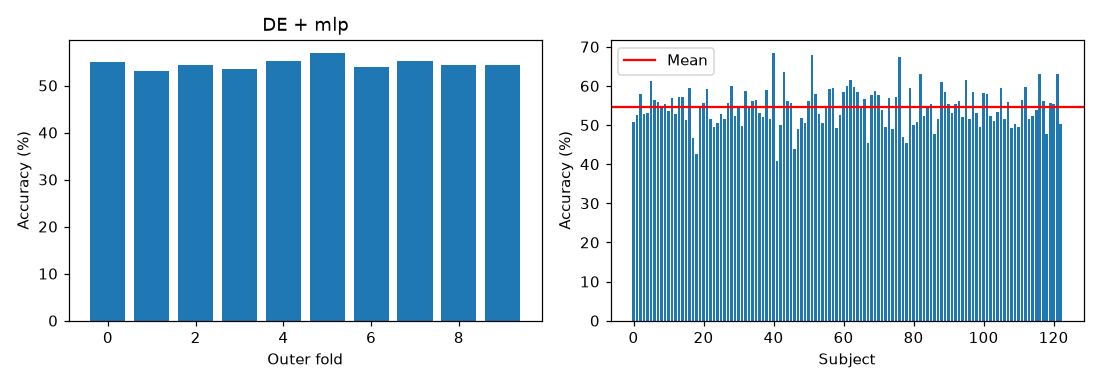

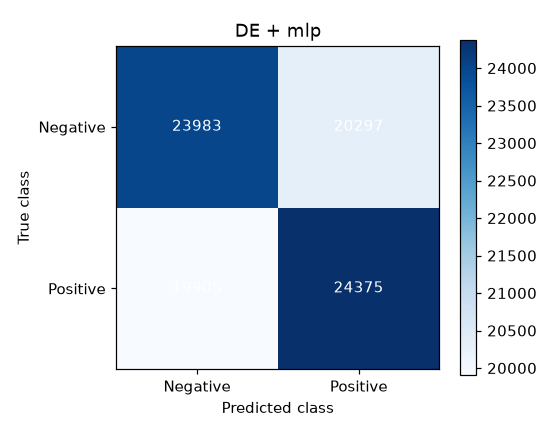

In [9]:
fig,axes = plt.subplots(1,2,figsize=(10,3.5))
axes[0].bar(np.arange(10),[100*r['test']['accuracy'] for r in results['folds']])
axes[0].set(xlabel='Outer fold',ylabel='Accuracy (%)',title='DE + '+model_kind)
axes[1].bar(subject_results['subject'],100*subject_results['accuracy'])
axes[1].axhline(100*results['accuracy'],color='red',label='Mean')
axes[1].set(xlabel='Subject',ylabel='Accuracy (%)'); axes[1].legend()
fig.tight_layout(); plt.show()
matrix = confusion_matrix(targets.ravel(),predictions.ravel(),labels=[0,1])
fig,ax = plt.subplots(figsize=(5,4)); image = ax.imshow(matrix,cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted class',ylabel='True class',title='DE + '+model_kind)
ax.set_xticklabels(class_names); ax.set_yticklabels(class_names)
fig.colorbar(image,ax=ax); fig.tight_layout(); plt.show()